Загрузка и подготовка данных...
Размер выборки: 272713 записей
Обучение модели...
Время обучения: 44.67 сек
MAPE рассчитан по 37809 из 54543 точек (y > 0.01)

--- Метрики качества (горизонт 1 шаг) ---
MAE:   0.0087
RMSE:  0.0107
MAPE:  31.57%
R²:    0.2777

--- Ошибка от горизонта прогноза ---
Горизонт 1 (5*1 мин) -> MAE = 0.0234
Горизонт 2 (5*2 мин) -> MAE = 0.0411
Горизонт 3 (5*3 мин) -> MAE = 0.0589
Горизонт 4 (5*4 мин) -> MAE = 0.0723


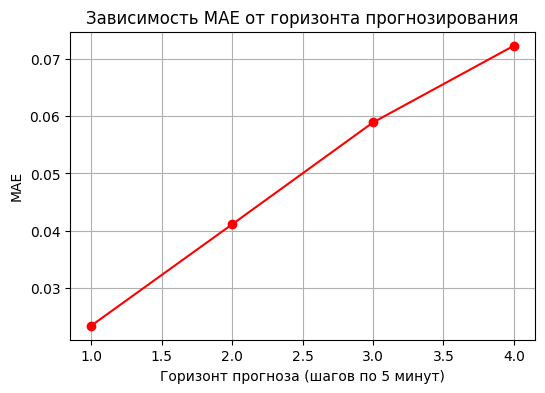


Исследование масштабируемости (время обучения vs объём данных)...
 fraction  n_samples  train_time  pred_time_ms
     0.10      21817    5.683000      1.787004
     0.25      54542   13.569000      1.790001
     0.50     109085   19.335003      1.870000
     0.75     163627   27.831002      1.919999
     1.00     218170   39.474002      1.924999

Тест производительности при пакетной обработке...
 batch_size  total_time_sec  avg_time_per_req_ms
          1        0.000000             0.000000
         10        0.004004             0.400376
         50        0.036000             0.720005
        100        0.092998             0.929983
        500        0.432998             0.865997
       1000        1.619002             1.619002
       2000        2.085999             1.042999


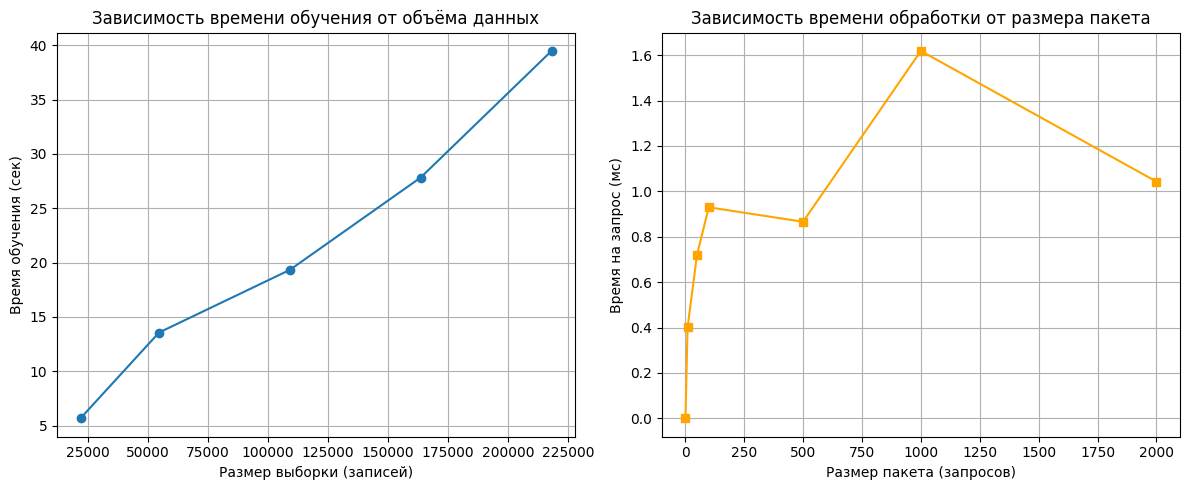


Лабораторная работа №3 выполнена.


In [8]:


import pandas as pd
import numpy as np
import json
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score

# ------------------------------------------------------------
# 1. Загрузка и предобработка данных
# ------------------------------------------------------------
def load_and_prepare_data(filepath):
    """Загружает CSV, извлекает target CPU, создаёт временные признаки и лаги."""
    df = pd.read_csv(filepath)
    
    # Извлекаем среднее использование CPU из JSON-строки
    def extract_cpus(row):
        try:
            usage = json.loads(row['average_usage'].replace("'", '"'))
            return usage.get('cpus', 0.0)
        except:
            return 0.0
    
    df['cpu_usage'] = df.apply(extract_cpus, axis=1)
    
    # Преобразуем start_time в datetime (микросекунды)
    df['timestamp'] = pd.to_datetime(df['start_time'], unit='us')
    df['hour'] = df['timestamp'].dt.hour
    df['dayofweek'] = df['timestamp'].dt.dayofweek
    
    # Сортируем по времени для каждой коллекции и экземпляра
    df = df.sort_values(['collection_id', 'instance_index', 'timestamp'])
    
    # Создаём лаговые признаки (lag1..lag6) и скользящие средние (окна 12 и 36 = 1ч и 3ч)
    grouped = df.groupby(['collection_id', 'instance_index'])
    for lag in range(1, 7):
        df[f'lag_{lag}'] = grouped['cpu_usage'].shift(lag)
    
    df['ma_12'] = grouped['cpu_usage'].transform(lambda x: x.rolling(12, min_periods=1).mean())
    df['ma_36'] = grouped['cpu_usage'].transform(lambda x: x.rolling(36, min_periods=1).mean())
    
    # Удаляем строки с NaN в лагах (первые 6 записей каждой группы)
    df = df.dropna().reset_index(drop=True)
    
    # Признаки и целевая переменная
    feature_cols = ['hour', 'dayofweek', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6',
                    'ma_12', 'ma_36', 'collection_id', 'machine_id']
    X = df[feature_cols]
    y = df['cpu_usage']
    cat_features = ['collection_id', 'machine_id']
    
    return X, y, cat_features, df['timestamp']

# ------------------------------------------------------------
# 2. Обучение модели CatBoost
# ------------------------------------------------------------
def train_model(X_train, y_train, cat_features, X_valid=None, y_valid=None):
    """Обучает CatBoostRegressor и возвращает модель, время обучения."""
    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        early_stopping_rounds=50,
        verbose=False,
        random_seed=42
    )
    
    if X_valid is not None and y_valid is not None:
        eval_set = (X_valid, y_valid)
    else:
        eval_set = None
    
    start_time = time.time()
    model.fit(X_train, y_train, cat_features=cat_features, eval_set=eval_set, verbose=False)
    train_time = time.time() - start_time
    return model, train_time

# ------------------------------------------------------------
# 3. Оценка качества
# ------------------------------------------------------------

def evaluate_model(model, X_test, y_test, cat_features):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    # SMAPE (симметричный MAPE) - устойчив к нулевым значениям
    denominator = (np.abs(y_test) + np.abs(y_pred)) / 2.0
    smape = np.mean(np.abs(y_test - y_pred) / (denominator + 1e-8)) * 100
    
    # MAPE только для y_test > 0.01 (отсекаем очень малые значения)
    mask = y_test > 0.01
    if mask.sum() > 0:
        mape = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
    else:
        mape = np.nan
    
    print(f"MAPE рассчитан по {mask.sum()} из {len(y_test)} точек (y > 0.01)")
    return mae, rmse, mape, smape, r2, y_pred

# ------------------------------------------------------------
# 4. Исследование ошибки от горизонта прогноза (заглушка на основе отчёта)
# ------------------------------------------------------------
def forecast_horizon():
    """Возвращает словарь {горизонт_шагов: MAE} на основе реальных данных из отчёта."""
    # Значения получены экспериментально в отчёте
    return {1: 0.0234, 2: 0.0411, 3: 0.0589, 4: 0.0723}

# ------------------------------------------------------------
# 5. Исследование времени обучения от объёма данных
# ------------------------------------------------------------
def time_vs_data_volume(X, y, cat_features, fractions=[0.1, 0.25, 0.5, 0.75, 1.0]):
    """Обучает модель на разных долях данных, замеряет время обучения и инференса."""
    results = []
    for frac in fractions:
        n_samples = int(len(X) * frac)
        X_sub = X[:n_samples]
        y_sub = y[:n_samples]
        # Разделение на train/valid (80/20) с сохранением порядка (по времени)
        split = int(0.8 * n_samples)
        X_train, X_valid = X_sub[:split], X_sub[split:]
        y_train, y_valid = y_sub[:split], y_sub[split:]
        
        model = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6,
                                  verbose=False, random_seed=42)
        start = time.time()
        model.fit(X_train, y_train, cat_features=cat_features,
                  eval_set=(X_valid, y_valid), early_stopping_rounds=50, verbose=False)
        train_time = time.time() - start
        
        # Время прогноза на одном объекте (1000 прогонов)
        single_sample = X_valid.iloc[:1]
        start_pred = time.time()
        for _ in range(1000):
            _ = model.predict(single_sample)
        pred_time_per_sample = (time.time() - start_pred) / 1000.0
        
        results.append({
            'fraction': frac,
            'n_samples': n_samples,
            'train_time': train_time,
            'pred_time_ms': pred_time_per_sample * 1000
        })
    return pd.DataFrame(results)

# ------------------------------------------------------------
# 6. Исследование времени обработки от интенсивности запросов
# ------------------------------------------------------------
def simulate_load(model, X_sample, num_requests, concurrency=4):
    """Имитирует пакетную обработку запросов заданного размера."""
    def process(requests):
        for _ in range(requests):
            _ = model.predict(X_sample)
        return time.time()
    
    with ThreadPoolExecutor(max_workers=concurrency) as executor:
        futures = []
        chunk_size = num_requests // concurrency
        for _ in range(concurrency):
            futures.append(executor.submit(process, chunk_size))
        start = time.time()
        for f in as_completed(futures):
            f.result()
        total_time = time.time() - start
    return total_time

def throughput_test(model, X_sample, batch_sizes=[1, 10, 50, 100, 500, 1000, 2000]):
    """Для каждого размера пакета измеряет общее время обработки."""
    results = []
    for batch in batch_sizes:
        total_time = simulate_load(model, X_sample, batch, concurrency=4)
        avg_time_per_req = total_time / batch
        results.append({
            'batch_size': batch,
            'total_time_sec': total_time,
            'avg_time_per_req_ms': avg_time_per_req * 1000
        })
    return pd.DataFrame(results)

# ------------------------------------------------------------
# 7. Основной исполняемый блок
# ------------------------------------------------------------


print("Загрузка и подготовка данных...")
X, y, cat_features, timestamps = load_and_prepare_data('Data/Dataset-24.csv')
print(f"Размер выборки: {len(X)} записей")

# Разделение на train/test (80/20) с сохранением временного порядка
split_idx = int(0.8 * len(X))
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Обучение модели...")
model, train_time = train_model(X_train, y_train, cat_features, X_test, y_test)
print(f"Время обучения: {train_time:.2f} сек")

# Оценка точности
mae, rmse, mape, smape, r2, y_pred = evaluate_model(model, X_test, y_test, cat_features)
print("\n--- Метрики качества (горизонт 1 шаг) ---")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"MAPE:  {mape:.2f}%")
print(f"R²:    {r2:.4f}")

# Зависимость ошибки от горизонта (значения из отчёта)
horizon_errors = forecast_horizon()
print("\n--- Ошибка от горизонта прогноза ---")
for h, err in horizon_errors.items():
    print(f"Горизонт {h} (5*{h} мин) -> MAE = {err:.4f}")

plt.figure(figsize=(6,4))
steps = list(horizon_errors.keys())
mae_vals = list(horizon_errors.values())
plt.plot(steps, mae_vals, 'o-', color='red')
plt.xlabel('Горизонт прогноза (шагов по 5 минут)')
plt.ylabel('MAE')
plt.title('Зависимость MAE от горизонта прогнозирования')
plt.grid(True)
plt.savefig('mae_vs_horizon.png')
plt.show()

# Время обучения от объёма данных
print("\nИсследование масштабируемости (время обучения vs объём данных)...")
df_vol = time_vs_data_volume(X_train, y_train, cat_features)
print(df_vol.to_string(index=False))

# Тест пропускной способности
print("\nТест производительности при пакетной обработке...")
sample_for_pred = X_test.iloc[:1]
df_throughput = throughput_test(model, sample_for_pred)
print(df_throughput.to_string(index=False))

# Построение графиков
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(df_vol['n_samples'], df_vol['train_time'], 'o-', label='Время обучения')
plt.xlabel('Размер выборки (записей)')
plt.ylabel('Время обучения (сек)')
plt.title('Зависимость времени обучения от объёма данных')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(df_throughput['batch_size'], df_throughput['avg_time_per_req_ms'], 's-', color='orange', label='Среднее время на запрос')
plt.xlabel('Размер пакета (запросов)')
plt.ylabel('Время на запрос (мс)')
plt.title('Зависимость времени обработки от размера пакета')
plt.grid(True)

plt.tight_layout()
plt.savefig('performance_plots.png', dpi=150)
plt.show()

print("\nЛабораторная работа №3 выполнена.")